# Домашнее задание: Деревья решений и их внутренняя механика


### Цели работы
1.  Реализовать алгоритм построения дерева решений  с нуля.
2.  Исследовать Bias-Variance Tradeoff на примере гиперпараметра `max_depth`.
3.  Понять ограничения деревьев (экстраполяция).
4.  Научиться интерпретировать модель через `feature_importances_`.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_moons, make_regression
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.metrics import accuracy_score, mean_squared_error

# Фиксация random_state для воспроизводимости
RANDOM_STATE = 42
plt.style.use('ggplot')

## Теория: Энтропия и деревья решений

Деревья решений принимают решения о разбиении данных, основываясь на идее **уменьшения неопределённости**. Давайте разберёмся, что это значит.

### Интуиция: неопределённость = перемешанность классов

Представьте корзину с шарами двух цветов: красными и синими.
- Если все шары одного цвета — неопределённости нет, мы точно знаем, какой цвет достанем.
- Если шары перемешаны 50/50 — максимальная неопределённость, мы ничего не знаем заранее.

### Энтропия Шеннона (для классификации)

В теории информации эта "неопределённость" измеряется **энтропией**. Для бинарной классификации:

$$H(p) = -p \log_2(p) - (1-p) \log_2(1-p)$$

где $p$ — доля объектов одного класса.

**Крайние случаи:**
- $p = 0$ или $p = 1$ → $H = 0$ (чистый узел, неопределённости нет)
- $p = 0.5$ → $H = 1$ (максимальная неопределённость, классы перемешаны)

### Information Gain

Дерево решений ищет разбиение, которое максимально уменьшает энтропию:

$$IG = H(\text{parent}) - \sum \frac{n_i}{n} H(\text{child}_i)$$

Чем больше Information Gain, тем "чище" становятся дочерние узлы после разбиения.

### Gini Impurity

На практике часто используют **Gini Impurity** — она быстрее вычисляется (нет логарифма):

$$\text{Gini} = 1 - \sum p_i^2$$

Для бинарного случая: $\text{Gini} = 1 - p^2 - (1-p)^2 = 2p(1-p)$

Обе метрики имеют похожий смысл: **чем ниже значение, тем "чище" узел**.

---

### Критерий для регрессии: MSE (дисперсия)

Для задач регрессии целевая переменная — непрерывное число, а не класс. Поэтому вместо "чистоты классов" мы измеряем **разброс значений**.

**MSE (Mean Squared Error)** в узле:

$$\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \bar{y})^2 = \text{Var}(y)$$

где $\bar{y}$ — среднее значение целевой переменной в узле.

**Интуиция:**
- Если все $y_i$ одинаковые → MSE = 0 (идеальный узел)
- Если значения сильно разбросаны → MSE высокое (плохой узел)

**Предсказание в листе:** для регрессии это просто **среднее значение** $\bar{y}$ всех обучающих примеров, попавших в этот лист.

### Сводка: классификация vs регрессия

|                  | Классификация                          | Регрессия                    |
|------------------|----------------------------------------|------------------------------|
| Целевая переменная | Класс (0, 1, 2, ...)                  | Число (вещественное)         |
| Критерий расщепления | Gini Impurity или Entropy           | MSE (дисперсия)              |
| Предсказание в листе | Самый частый класс (mode)           | Среднее значение (mean)      |

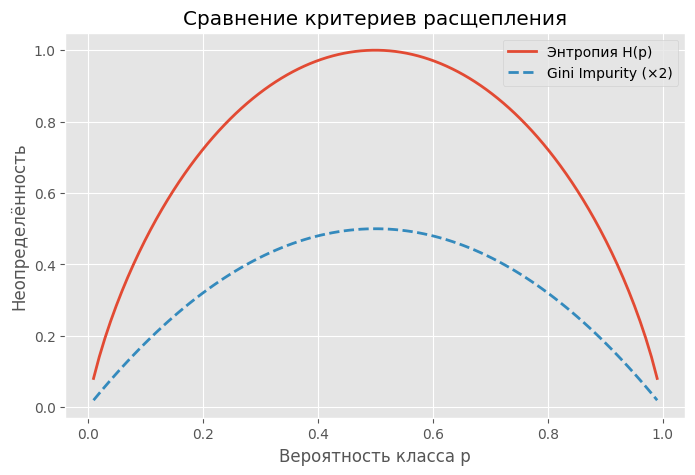

In [2]:
# Визуализация энтропии и Gini Impurity
p = np.linspace(0.01, 0.99, 100)
entropy = -p * np.log2(p) - (1 - p) * np.log2(1 - p)
gini = 2 * p * (1 - p)  # масштабированная Gini для сравнения

plt.figure(figsize=(8, 5))
plt.plot(p, entropy, label='Энтропия H(p)', linewidth=2)
plt.plot(p, gini, label='Gini Impurity (×2)', linewidth=2, linestyle='--')
plt.xlabel('Вероятность класса p')
plt.ylabel('Неопределённость')
plt.title('Сравнение критериев расщепления')
plt.legend()
plt.grid(True)
plt.show()

## Задание 0. Реализация Дерева Решений

**Это задание повышенной сложности.** Вам необходимо реализовать алгоритм CART (Classification and Regression Trees) самостоятельно, заполнив пропуски в классах ниже

Эти классы **будут использованы в домашнем задании 6**  для построения Случайного Леса вручную

**Требования:**

1. Реализовать расчет Gini Impurity и MSE.
2. Реализовать поиск лучшего разбиения (`_best_split`).
3. Реализовать рекурсивное построение дерева (`_grow_tree`).
4. Реализовать проход по дереву для предсказания (`_traverse_tree`).

In [3]:
import numpy as np
from collections import Counter

class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, *, value=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value

    def is_leaf_node(self):
        return self.value is not None

class MyBaseDecisionTree:
    def __init__(self, max_depth=100, min_samples_split=2):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.root = None

    def fit(self, X, y):
        self.root = self._grow_tree(np.array(X), np.array(y))

    def _grow_tree(self, X, y, depth=0):
        n_samples, n_feats = X.shape
        n_labels = len(np.unique(y))

        #TODO: Реализуйте критерии остановки (depth >= max_depth, n_labels == 1, n_samples < min_samples)
        # if ...:
        #    leaf_value = self._calculate_leaf_value(y)
        #    return Node(value=leaf_value)
        if (depth >= self.max_depth or n_labels == 1 or n_samples < self.min_samples_split):
            leaf_value = self._calculate_leaf_value(y)
            return Node(value=leaf_value)

        feat_idx, thresh = self._best_split(X, y, n_feats)

        if feat_idx is None:
            leaf_value = self._calculate_leaf_value(y)
            return Node(value=leaf_value)
        # Если сплит не найден
        # ...
        left_idxs = np.argwhere(X[:, feat_idx] <= thresh).flatten()
        right_idxs = np.argwhere(X[:, feat_idx] > thresh).flatten()
        #TODO: Создайте индексы для левой и правой ветки и вызовите рекурсию
        # left_idxs, right_idxs = ...
        left = self._grow_tree(X[left_idxs], y[left_idxs], depth + 1)
        right = self._grow_tree(X[right_idxs], y[right_idxs], depth+1)
        
        return Node(feature=feat_idx, threshold=thresh, left=left, right=right)

    def _best_split(self, X, y, n_feats):
        best_gain = -1
        split_idx, split_thresh = None, None

        #TODO: Перебор признаков и порогов для поиска максимального Information Gain
        for feat_idx in range(n_feats):
            X_col = X[:, feat_idx]
            thresholds = np.unique(X_col)

            for thresh in thresholds:
                left_idxs = np.argwhere(X_col <= thresh).flatten()
                right_idxs = np.argwhere(X_col > thresh).flatten()

                if len(left_idxs) == 0 or len(right_idxs) == 0:
                    continue

                n = len(y)
                n_l, n_r = len(left_idxs), len(right_idxs)

                parent_imp = self._calculate_impurity(y)
                left_imp = self._calculate_impurity(y[left_idxs])
                right_imp = self._calculate_impurity(y[right_idxs])

                child_imp = (n_l / n) * left_imp + (n_r / n) * right_imp
                gain = parent_imp - child_imp

                if gain > best_gain:
                    best_gain = gain
                    split_idx = feat_idx
                    split_thresh = thresh
        return split_idx, split_thresh

    def _calculate_leaf_value(self, y):
        raise NotImplementedError
    

    def _calculate_impurity(self, y):
        raise NotImplementedError

    def predict(self, X):
        return np.array([self._traverse_tree(x, self.root) for x in np.array(X)])

    def _traverse_tree(self, x, node):
        #TODO: Реализуйте проход по дереву до листа
        if node.is_leaf_node():
            return node.value

        if x[node.feature] <= node.threshold:
            return self._traverse_tree(x, node.left)
        return self._traverse_tree(x, node.right)


In [4]:
# КЛАССИФИКАЦИЯ
class MyDecisionTreeClassifier(MyBaseDecisionTree):
    def _calculate_impurity(self, y):
        #TODO: Реализовать Gini Impurity = 1 - sum(p^2)
        proportions = np.bincount(y) / len(y)
        return 1 - np.sum(proportions ** 2)

    def _calculate_leaf_value(self, y):
        # Самый частый класс
        counter = Counter(y)
        return counter.most_common(1)[0][0]


In [5]:
# РЕГРЕССИЯ
class MyDecisionTreeRegressor(MyBaseDecisionTree):
    def _calculate_impurity(self, y):
        #TODO: Реализовать MSE / Variance
        return np.var(y)

    def _calculate_leaf_value(self, y):
        return np.mean(y)


## Самопроверка

In [6]:

print("Проверка Классификации")
X_test_cls, y_test_cls = make_moons(n_samples=100, noise=0.1, random_state=42)
my_clf = MyDecisionTreeClassifier(max_depth=3)
try:
    my_clf.fit(X_test_cls, y_test_cls)
    print("MyClassifier Accuracy:", accuracy_score(y_test_cls, my_clf.predict(X_test_cls)))
except Exception as e:
    print("Ошибка:", e)

print("=*50")
print("\nПроверка Регрессии ")
X_test_reg = np.array([[1], [2], [3], [4], [5]])
y_test_reg = np.array([1.1, 1.9, 3.1, 4.2, 4.8])
my_reg = MyDecisionTreeRegressor(max_depth=3)
try:
    my_reg.fit(X_test_reg, y_test_reg)
    print("MyRegressor MSE:", mean_squared_error(y_test_reg, my_reg.predict(X_test_reg)))
except Exception as e:
    print("Ошибка:", e)

Проверка Классификации
MyClassifier Accuracy: 0.93
=*50

Проверка Регрессии 
MyRegressor MSE: 0.0


## Задание 1. Поиск оптимальной глубины

Ваша задача - найти ту глубину (`max_depth`), при которой модель работает лучше всего на новых данных, но еще не начала запоминать шум.

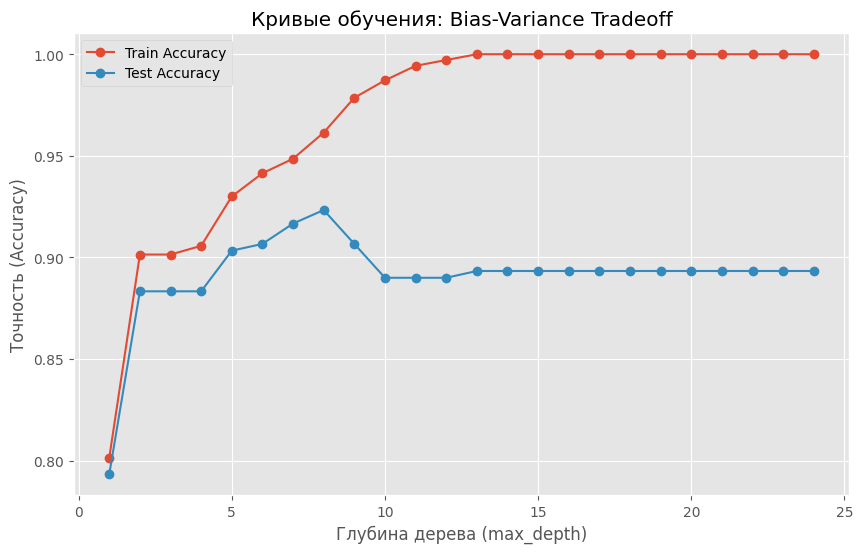

In [7]:
# 1. Генерация данных
X, y = make_moons(n_samples=1000, noise=0.3, random_state=RANDOM_STATE)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE)

train_scores = []
test_scores = []
depths = range(1, 25)

# 2. Цикл обучения
for depth in depths:
    # ВАШ КОД: Обучить DecisionTreeClassifier с max_depth=depth
    clf = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)
    clf.fit(X_train, y_train)

    # Сохраняем метрики
    train_scores.append(accuracy_score(y_train, clf.predict(X_train)))
    test_scores.append(accuracy_score(y_test, clf.predict(X_test)))

# 3. Визуализация
plt.figure(figsize=(10, 6))
plt.plot(depths, train_scores, label='Train Accuracy', marker='o')
plt.plot(depths, test_scores, label='Test Accuracy', marker='o')
plt.xlabel('Глубина дерева (max_depth)')
plt.ylabel('Точность (Accuracy)')
plt.title('Кривые обучения: Bias-Variance Tradeoff')
plt.legend()
plt.grid(True)
plt.show()


**Вопрос для самопроверки:**

На какой глубине кривая `test` достигает пика, а потом начинает падать (или выходить на плато), в то время как `train` продолжает расти? Обоснуйте выбор оптимальной глубины

## Задание 2. Проблема экстраполяции

Деревья решений не умеют предсказывать значения за пределами обучающего диапазона, так как в листьях содержится константное значение (среднее)
Продемонстрируйте это

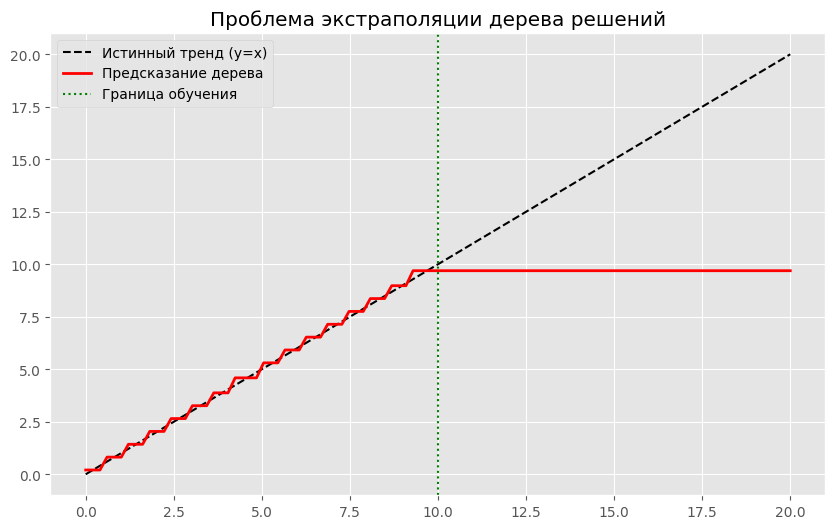

In [8]:
# Обучающие данные: Линия y = x от 0 до 10
X_train = np.linspace(0, 10, 50).reshape(-1, 1)
y_train = X_train.ravel()

# Тестовые данные: Линия от 0 до 20
X_test = np.linspace(0, 20, 100).reshape(-1, 1)
y_test_true = X_test.ravel()

# ВАШ КОД: Обучите DecisionTreeRegressor на X_train
reg = DecisionTreeRegressor(max_depth=4, random_state=RANDOM_STATE)
reg.fit(X_train, y_train)

y_pred = reg.predict(X_test)

# Визуализация
plt.figure(figsize=(10, 6))
plt.plot(X_test, y_test_true, 'k--', label='Истинный тренд (y=x)')
plt.plot(X_test, y_pred, 'r', label='Предсказание дерева', linewidth=2)
plt.axvline(x=10, color='g', linestyle=':', label='Граница обучения')
plt.legend()
plt.title('Проблема экстраполяции дерева решений')
plt.show()

## Задание 3. Интерпретация модели

Используйте датасет Titanic для анализа важности признаков

1. Предобработайте данные (удалите NaN, закодируйте пол).
2. Обучите дерево.
3. Выведите топ-3 самых важных признака.

/tmp/ipykernel_7882/3016375076.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importances, palette='viridis')


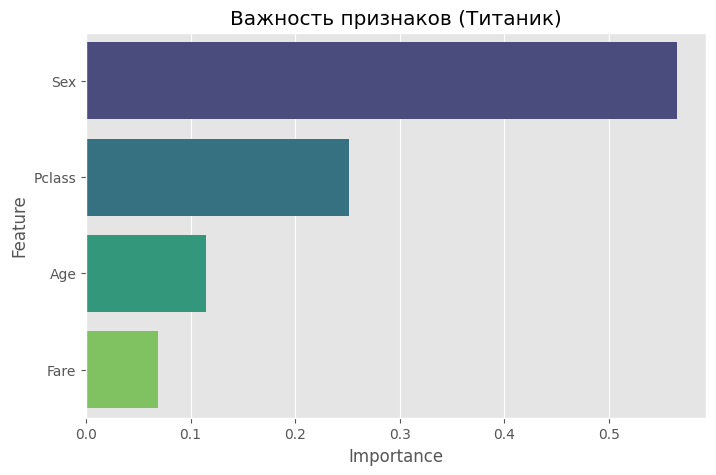

In [9]:
# Загрузка данных
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

# ВАШ КОД: Предобработка
# 1. Оставьте колонки ['Survived', 'Pclass', 'Sex', 'Age', 'Fare']
# 2. Удалите строки с NaN
# 3. Замените 'male'->0, 'female'->1
cols = ["Survived", "Pclass", "Sex", "Age", "Fare"]
df_clean = df[cols].dropna().copy()
df_clean["Sex"] = df_clean["Sex"].map({"male": 0, "female": 1})


X_titanic = df_clean.drop("Survived", axis=1)
y_titanic = df_clean["Survived"]

# ВАШ КОД: Обучение DecisionTreeClassifier (max_depth=4)
clf_titanic = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)
clf_titanic.fit(X_titanic, y_titanic)

# ВАШ КОД: Визуализация важности (sns.barplot)
importances = pd.DataFrame({
    "Feature": X_titanic.columns,
    "Importance": clf_titanic.feature_importances_
}).sort_values("Importance", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x='Importance', y='Feature', data=importances, palette='viridis')
plt.title('Важность признаков (Титаник)')
plt.show()


## Задание 4. Влияние регуляризации на границы

Исследуйте, как параметр `min_samples_leaf` влияет на сложность границы решений.
Обучите два дерева на датасете `make_moons`:
1. `min_samples_leaf=1` (стандартное переобучение)
2. `min_samples_leaf=20` (сглаживание)

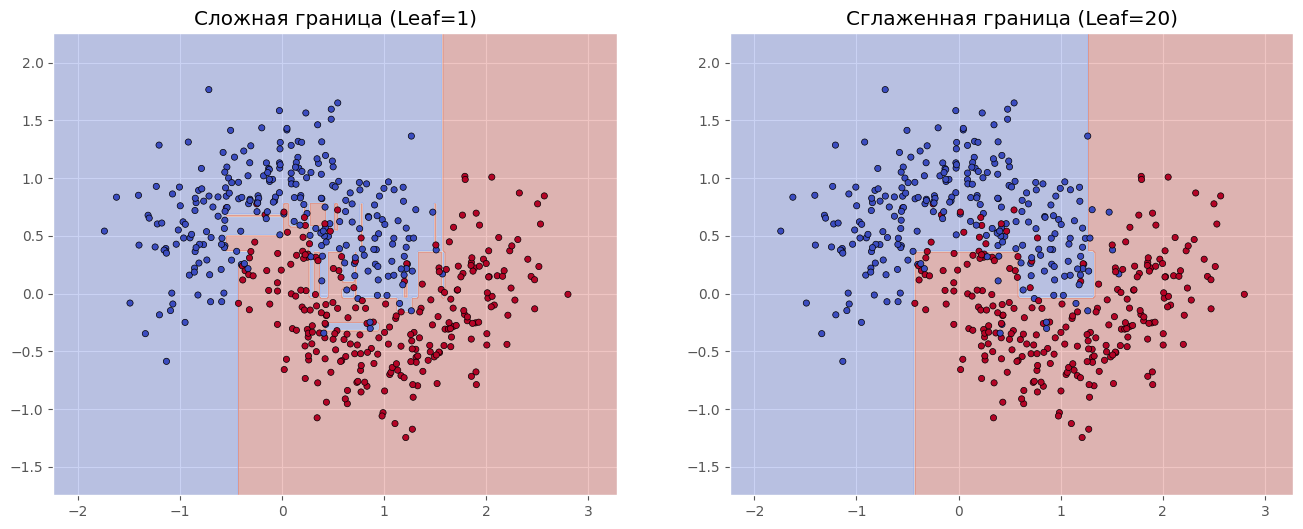

In [11]:
# Функция для отрисовки границ
def plot_boundary(model, X, y, ax, title):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap='coolwarm', alpha=0.3)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolor='k', s=20)
    ax.set_title(title)

X, y = make_moons(n_samples=500, noise=0.3, random_state=RANDOM_STATE)

# ВАШ КОД: Обучение моделей
tree_complex = DecisionTreeClassifier(min_samples_leaf=1, random_state=RANDOM_STATE)
tree_smooth = DecisionTreeClassifier(min_samples_leaf=20, random_state=RANDOM_STATE)

tree_complex.fit(X, y)
tree_smooth.fit(X, y)

# Визуализация
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
plot_boundary(tree_complex, X, y, ax[0], "Сложная граница (Leaf=1)")
plot_boundary(tree_smooth, X, y, ax[1], "Сглаженная граница (Leaf=20)")
plt.show()